## Main question: how well can a Naive Bayes classifier distinguish letters based on numerical image features?

We know that the data in this dataset is able to be classified rather well, but the models who had their performance measure did not include Naive Bayes classification, so we'll take a look for them!

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
columns = [
    "letter",
    "x_box", "y_box", "width", "height", "on_pixels",
    "x_bar", "y_bar", "x2bar", "y2bar", "xybar",
    "x2ybr", "xy2br", "x_edge", "xegvy", "y_edge", "yegvx"
]

df = pd.read_csv(
    "data/letter-recognition.data",
    header=None,
    names=columns
)
df.head()


,letter,x_box,y_box,width,height,on_pixels,x_bar,y_bar,x2bar,y2bar,xybar,x2ybr,xy2br,x_edge,xegvy,y_edge,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


In [3]:
print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()
print("\nNumerical feature summary:")
df.describe()


Dataset shape: (20000, 17)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   letter     20000 non-null  str  
 1   x_box      20000 non-null  int64
 2   y_box      20000 non-null  int64
 3   width      20000 non-null  int64
 4   height     20000 non-null  int64
 5   on_pixels  20000 non-null  int64
 6   x_bar      20000 non-null  int64
 7   y_bar      20000 non-null  int64
 8   x2bar      20000 non-null  int64
 9   y2bar      20000 non-null  int64
 10  xybar      20000 non-null  int64
 11  x2ybr      20000 non-null  int64
 12  xy2br      20000 non-null  int64
 13  x_edge     20000 non-null  int64
 14  xegvy      20000 non-null  int64
 15  y_edge     20000 non-null  int64
 16  yegvx      20000 non-null  int64
dtypes: int64(16), str(1)
memory usage: 2.6 MB

Numerical feature summary:


,x_box,y_box,width,height,on_pixels,x_bar,y_bar,x2bar,y2bar,xybar,x2ybr,xy2br,x_edge,xegvy,y_edge,yegvx
count,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000
mean,4.023550,7.035500,5.121850,5.37245,3.505850,6.897600,7.500450,4.628600,5.178650,8.282050,6.45400,7.929000,3.046100,8.338850,3.691750,7.80120
std,1.913212,3.304555,2.014573,2.26139,2.190458,2.026035,2.325354,2.699968,2.380823,2.488475,2.63107,2.080619,2.332541,1.546722,2.567073,1.61747
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,3.000000,5.000000,4.000000,4.00000,2.000000,6.000000,6.000000,3.000000,4.000000,7.000000,5.00000,7.000000,1.000000,8.000000,2.000000,7.00000
50%,4.000000,7.000000,5.000000,6.00000,3.000000,7.000000,7.000000,4.000000,5.000000,8.000000,6.00000,8.000000,3.000000,8.000000,3.000000,8.00000
75%,5.000000,9.000000,6.000000,7.00000,5.000000,8.000000,9.000000,6.000000,7.000000,10.000000,8.00000,9.000000,4.000000,9.000000,5.000000,9.00000
max,15.000000,15.000000,15.000000,15.00000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.00000,15.000000,15.000000,15.000000,15.000000,15.00000


Missing values per column:
letter       0
x_box        0
y_box        0
width        0
height       0
on_pixels    0
x_bar        0
y_bar        0
x2bar        0
y2bar        0
xybar        0
x2ybr        0
xy2br        0
x_edge       0
xegvy        0
y_edge       0
yegvx        0
dtype: int64

Number of duplicate rows: 1332

Number of unique letters: 26
Letters present: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

Feature minimums:
x_box        0
y_box        0
width        0
height       0
on_pixels    0
x_bar        0
y_bar        0
x2bar        0
y2bar        0
xybar        0
x2ybr        0
xy2br        0
x_edge       0
xegvy        0
y_edge       0
yegvx        0
dtype: int64

Feature maximums:
x_box        15
y_box        15
width        15
height       15
on_pixels    15
x_bar        15
y_bar        15
x2bar        15
y2bar        15
xybar        15
x2ybr        15
xy2br        15
x_edge      

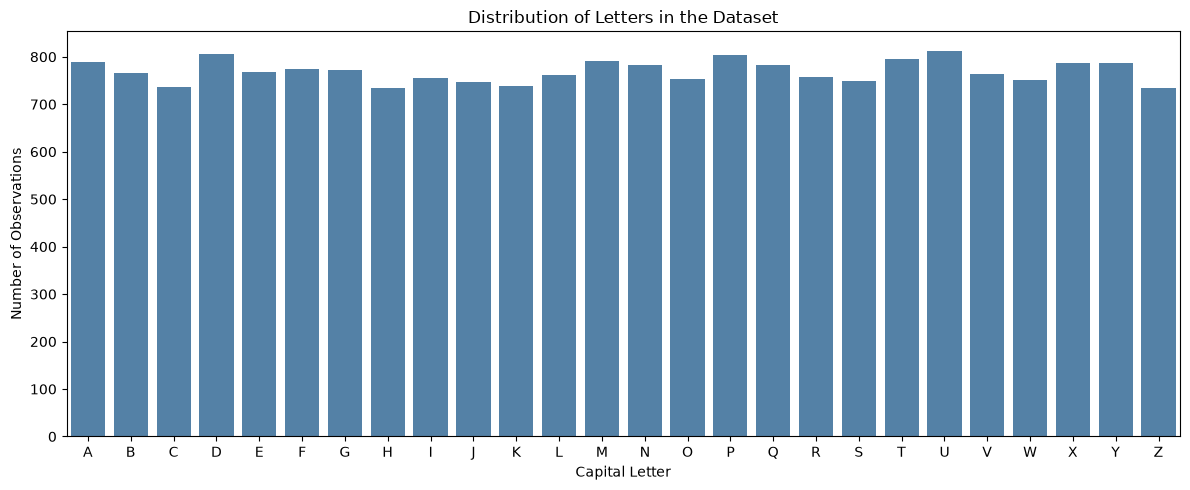

In [4]:
# Lets see if we need to do any data cleaning
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
print("\nNumber of unique letters:", df["letter"].nunique())
print("Letters present:", sorted(df["letter"].unique()))
print("\nFeature minimums:")
print(df.drop(columns="letter").min())
print("\nFeature maximums:")
print(df.drop(columns="letter").max())

# Count observations for each letter
letter_counts = df["letter"].value_counts().sort_index()
print("Observations per letter:")
print(letter_counts)
# Visualize the distribution
plt.figure(figsize=(12, 5))
sns.barplot(x=letter_counts.index, y=letter_counts.values, color="steelblue")
plt.title("Distribution of Letters in the Dataset")
plt.xlabel("Capital Letter")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

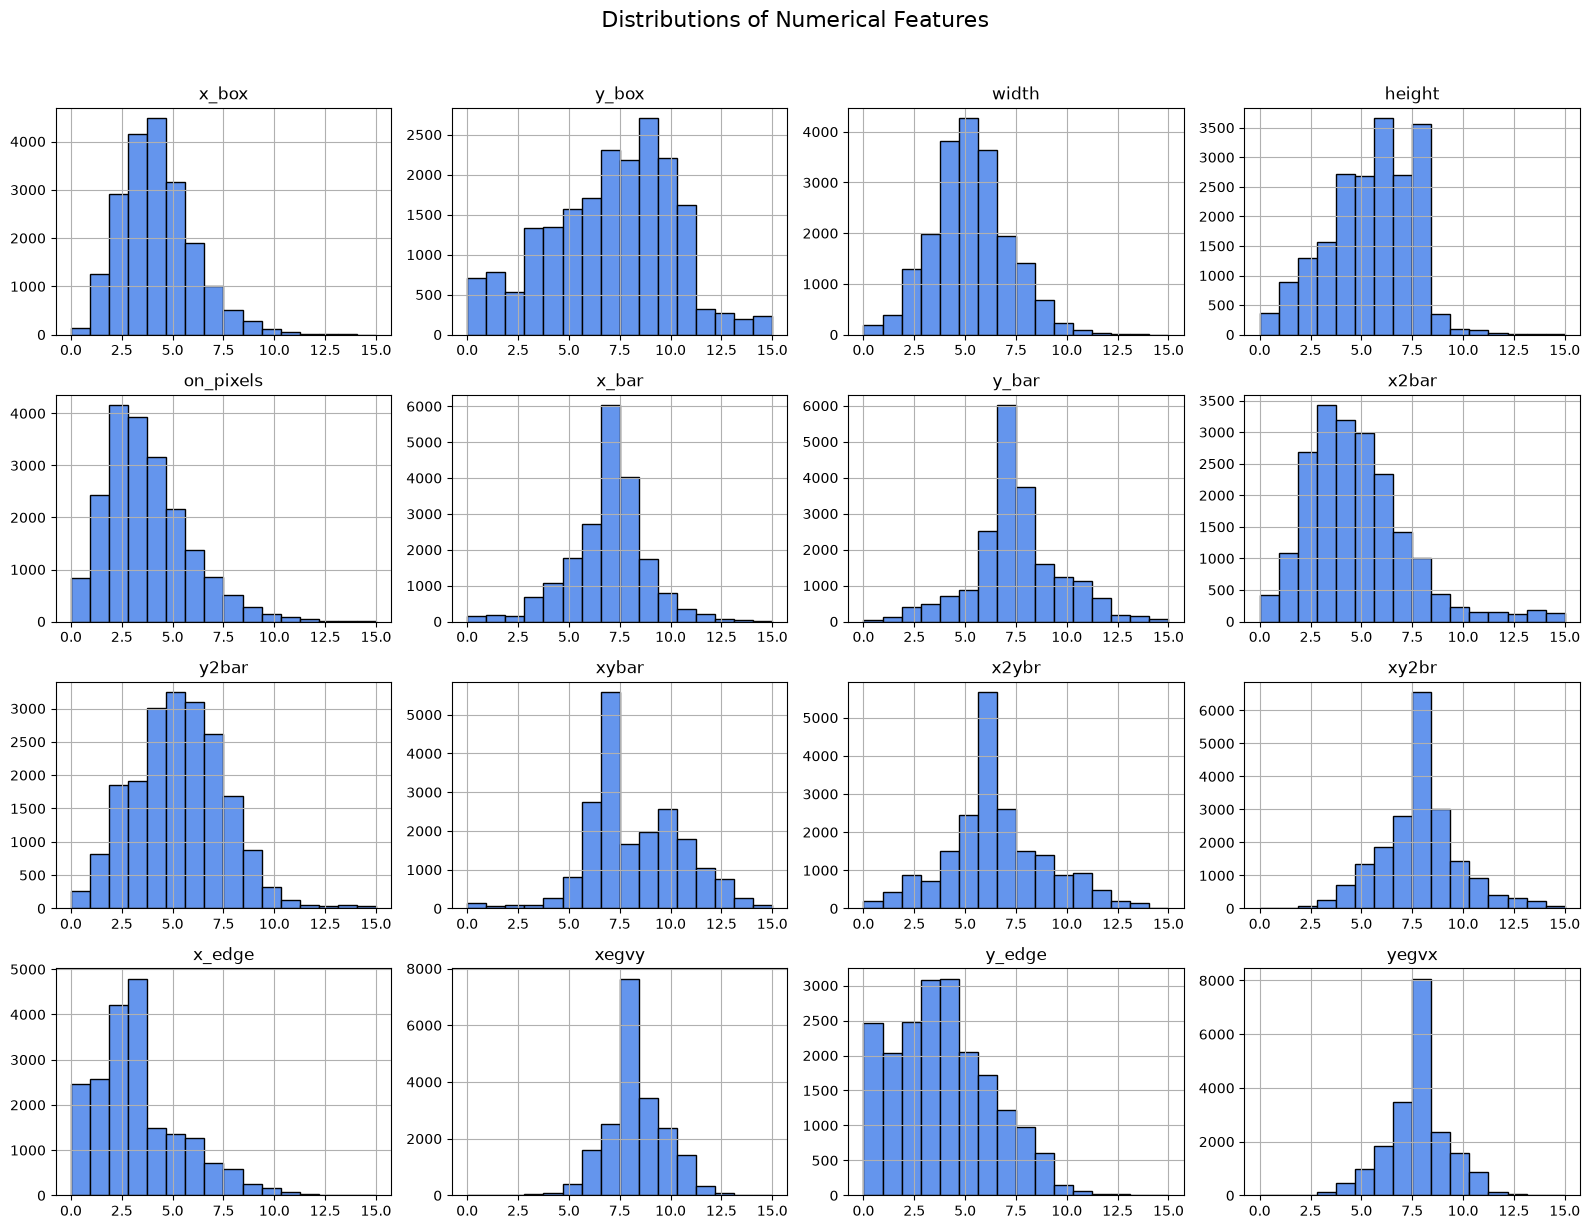

In [5]:
# Observing the numerical feature distributions
features = df.drop(columns="letter")
features.hist(
    figsize=(16, 12),
    bins=16,
    edgecolor="black",
    color="cornflowerblue"
)
plt.suptitle(
    "Distributions of Numerical Features",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.show()

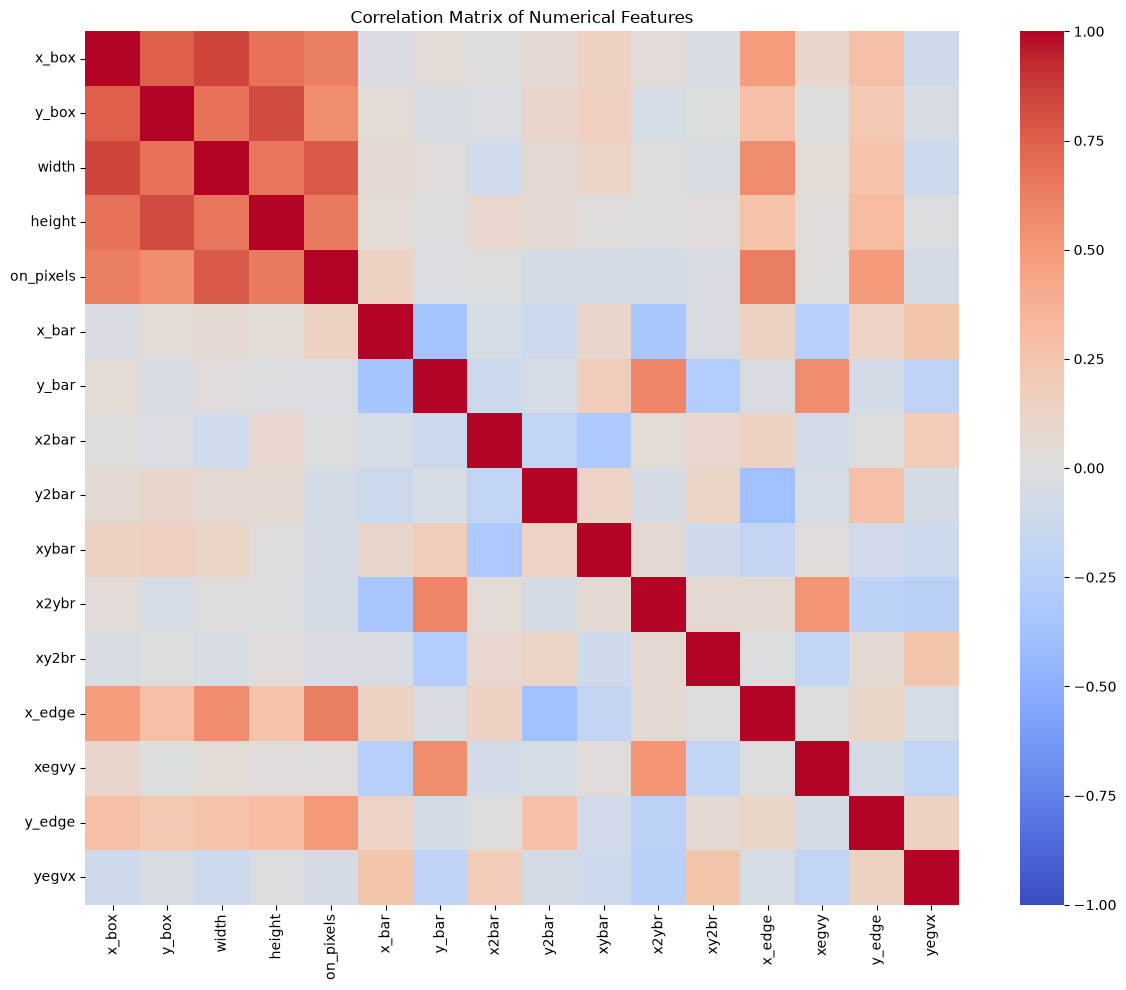

In [6]:
# Calculate correlations between numerical features
correlation_matrix = features.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


In [7]:
# Inveestigating duplicate rows
feature_columns = df.columns.drop("letter")
repeated_features = df.duplicated(
    subset=feature_columns,
    keep=False
)

duplicate_groups = df.loc[repeated_features]

# Count distinct labels associated with each feature vector
label_counts_per_vector = (
    duplicate_groups.groupby(list(feature_columns))["letter"]
    .nunique()
)

# Summarize the repeated feature vectors
print("Rows belonging to repeated feature vectors:",
      repeated_features.sum())

print("Repeated feature vectors:",
      len(label_counts_per_vector))

print("Feature vectors associated with multiple letters:",
      (label_counts_per_vector > 1).sum())

# Examine exact duplicate rows with their labels
print("\nMost frequently repeated complete observations:")
print(
    df.value_counts()
    .head(10)
    .rename("frequency")
)

Rows belonging to repeated feature vectors: 2177
Repeated feature vectors: 845
Feature vectors associated with multiple letters: 0

Most frequently repeated complete observations:
letter  x_box  y_box  width  height  on_pixels  x_bar  y_bar  x2bar  y2bar  xybar  x2ybr  xy2br  x_edge  xegvy  y_edge  yegvx
I       0      0      0      0       0          7      7      4      4      7      6      8      0       8      0       8        26
        1      10     0      7       0          7      7      4      4      7      6      8      0       8      0       8        14
        0      1      0      1       0          7      7      4      4      7      6      8      0       8      0       8        13
        1      9      0      6       0          7      7      4      4      7      6      8      0       8      0       8        10
X       3      9      4      6       1          7      7      4      4      7      6      8      3       8      4       8        10
I       0      6      0      4    

In [8]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
strongest_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .to_frame()
)
strongest_correlations["absolute_correlation"] = (
    strongest_correlations["correlation"].abs()
)
print(
    strongest_correlations
    .sort_values("absolute_correlation", ascending=False)
    .head(10)
)

                     correlation  absolute_correlation
x_box     width         0.851514              0.851514
y_box     height        0.823207              0.823207
width     on_pixels     0.765716              0.765716
x_box     y_box         0.757793              0.757793
          height        0.672764              0.672764
y_box     width         0.671912              0.671912
width     height        0.660215              0.660215
height    on_pixels     0.644366              0.644366
on_pixels x_edge        0.627507              0.627507
x_box     on_pixels     0.619097              0.619097


In [9]:
# Lets go modeling!
X = df.drop(columns="letter")
y = df["letter"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the resulting dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Verify class proportions
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training features: (16000, 16)
Testing features: (4000, 16)

Training target: (16000,)
Testing target: (4000,)

Training class proportions:
letter
A    0.039
B    0.038
C    0.037
D    0.040
E    0.038
F    0.039
G    0.039
H    0.037
I    0.038
J    0.037
K    0.037
L    0.038
M    0.040
N    0.039
O    0.038
P    0.040
Q    0.039
R    0.038
S    0.037
T    0.040
U    0.041
V    0.038
W    0.038
X    0.039
Y    0.039
Z    0.037
Name: proportion, dtype: float64

Testing class proportions:
letter
A    0.040
B    0.038
C    0.037
D    0.040
E    0.038
F    0.039
G    0.039
H    0.037
I    0.038
J    0.037
K    0.037
L    0.038
M    0.040
N    0.039
O    0.038
P    0.040
Q    0.039
R    0.038
S    0.038
T    0.040
U    0.041
V    0.038
W    0.038
X    0.039
Y    0.039
Z    0.037
Name: proportion, dtype: float64


In [10]:
# Gaussian Naive Bayes Model
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Generate predictions on unseen test rows
y_pred = gnb.predict(X_test)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)
# print(f"Gaussian Naive Bayes test accuracy: {accuracy:.4f}")
print(f"Gaussian Naive Bayes test accuracy: {accuracy:.2%}")

# Detailed classification metrics
print(
    classification_report(
        y_test,
        y_pred,
        labels=sorted(y.unique()),
        zero_division=0
    )
)

Gaussian Naive Bayes test accuracy: 65.22%
              precision    recall  f1-score   support

           A       0.85      0.87      0.86       158
           B       0.48      0.72      0.57       153
           C       0.80      0.82      0.81       147
           D       0.61      0.71      0.66       161
           E       0.61      0.38      0.47       154
           F       0.70      0.77      0.73       155
           G       0.59      0.55      0.57       155
           H       0.58      0.35      0.44       147
           I       0.52      0.71      0.60       151
           J       0.83      0.71      0.77       149
           K       0.49      0.49      0.49       148
           L       0.91      0.78      0.84       152
           M       0.69      0.88      0.77       158
           N       0.89      0.68      0.77       157
           O       0.48      0.74      0.58       150
           P       0.87      0.78      0.82       161
           Q       0.53      0.51     

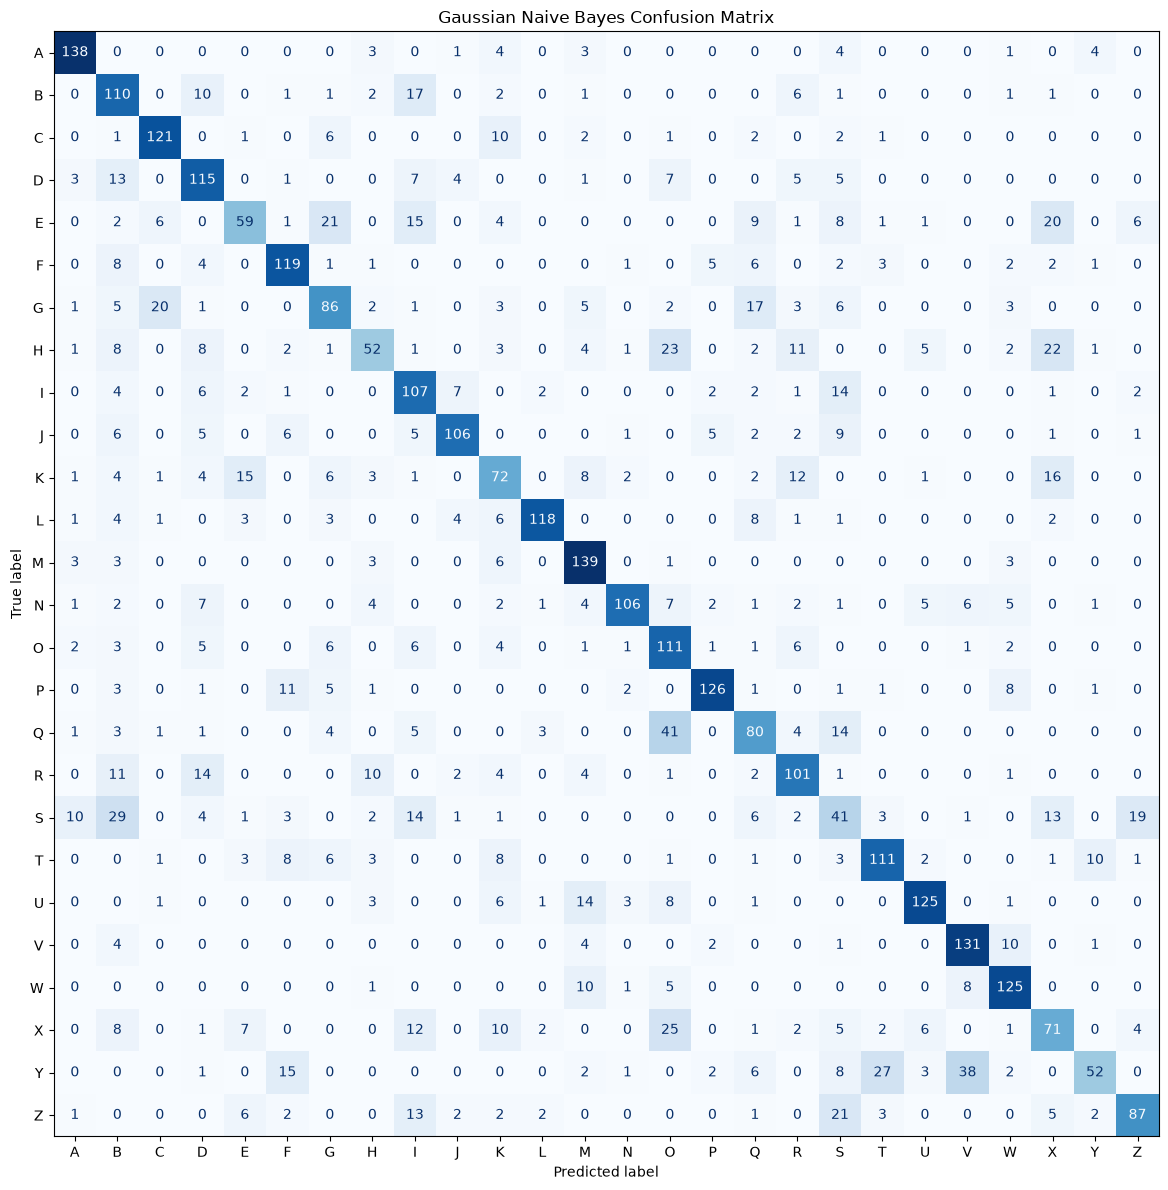

Ten most common misclassifications:
Q  O    41
Y  V    38
S  B    29
Y  T    27
X  O    25
H  O    23
   X    22
E  G    21
Z  S    21
G  C    20
dtype: int64


In [11]:
# Calculate the confusion matrix
labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Convert the confusion matrix to a DataFrame
cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)
errors = cm_df.to_numpy(copy=True)

# Exclude correct predictions along the diagonal
np.fill_diagonal(errors, 0)

# Convert back to a DataFrame
errors_df = pd.DataFrame(
    errors,
    index=labels,
    columns=labels
)

# Find the ten most frequent incorrect predictions
most_common_errors = (
    errors_df.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Ten most common misclassifications:")
print(most_common_errors)

In [12]:
# Multinomial Naive Bayes - lets see how it performs just to check

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

# Predict on the same test set
y_pred_mnb = mnb.predict(X_test)
mnb_accuracy = accuracy_score(y_test, y_pred_mnb)

# print(f"Multinomial Naive Bayes test accuracy: {mnb_accuracy:.4f}")
print(f"Multinomial Naive Bayes test accuracy: {mnb_accuracy:.2%}")

Multinomial Naive Bayes test accuracy: 55.53%


                  Model  Test Accuracy
   Gaussian Naive Bayes        0.65225
Multinomial Naive Bayes        0.55525


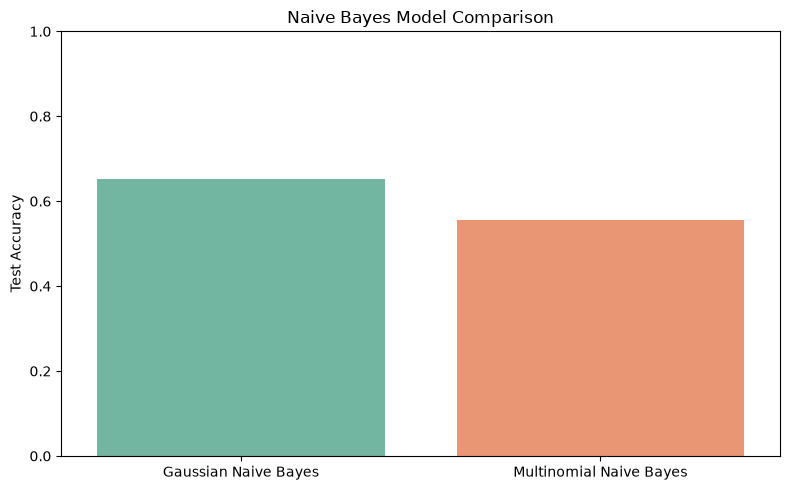

In [13]:
# Compare test-set performance
model_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_mnb)
    ]
})

print(model_comparison.to_string(index=False))

# Visualize the comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Test Accuracy",
    hue="Model",
    legend=False,
    palette="Set2"
)

plt.ylim(0, 1)
plt.title("Naive Bayes Model Comparison")
plt.ylabel("Test Accuracy")
plt.xlabel("")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

# Give identical feature vectors the same group ID
groups = pd.factorize(pd.MultiIndex.from_frame(X))[0]

# Create a stratified, group-aware split to more rigourously check it
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    group_splitter.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

# Verify that no feature-vector groups cross the split
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print("Training observations:", len(train_idx))
print("Testing observations:", len(test_idx))
print("Shared feature-vector groups:",
      len(train_groups.intersection(test_groups)))

print("\nTraining letter distribution:")
print(y_train_group.value_counts().sort_index())

print("\nTesting letter distribution:")
print(y_test_group.value_counts().sort_index())

Training observations: 16000
Testing observations: 4000
Shared feature-vector groups: 0

Training letter distribution:
letter
A    631
B    613
C    589
D    644
E    614
F    620
G    618
H    587
I    604
J    598
K    591
L    609
M    634
N    627
O    602
P    643
Q    627
R    606
S    598
T    637
U    650
V    612
W    601
X    629
Y    629
Z    587
Name: count, dtype: int64

Testing letter distribution:
letter
A    158
B    153
C    147
D    161
E    154
F    155
G    155
H    147
I    151
J    149
K    148
L    152
M    158
N    156
O    151
P    160
Q    156
R    152
S    150
T    159
U    163
V    152
W    151
X    158
Y    157
Z    147
Name: count, dtype: int64


In [15]:
# Train Gaussian Naive Bayes
gnb_group = GaussianNB()
gnb_group.fit(X_train_group, y_train_group)

pred_gnb_group = gnb_group.predict(X_test_group)

# Train Multinomial Naive Bayes on the same split
mnb_group = MultinomialNB()
mnb_group.fit(X_train_group, y_train_group)

pred_mnb_group = mnb_group.predict(X_test_group)

# Compare grouped-split accuracy
group_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Grouped Test Accuracy": [
        accuracy_score(y_test_group, pred_gnb_group),
        accuracy_score(y_test_group, pred_mnb_group)
    ]
})

print(group_comparison.to_string(index=False))

                  Model  Grouped Test Accuracy
   Gaussian Naive Bayes                  0.653
Multinomial Naive Bayes                  0.554


In [16]:
# Combine the random-split and grouped-split results
evaluation_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Random Split Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_mnb)
    ],
    "Grouped Split Accuracy": [
        accuracy_score(y_test_group, pred_gnb_group),
        accuracy_score(y_test_group, pred_mnb_group)
    ]
})

print(evaluation_comparison.to_string(index=False))


                  Model  Random Split Accuracy  Grouped Split Accuracy
   Gaussian Naive Bayes                0.65225                   0.653
Multinomial Naive Bayes                0.55525                   0.554


              precision    recall  f1-score   support

           A       0.85      0.87      0.86       158
           B       0.50      0.73      0.59       153
           C       0.80      0.74      0.77       147
           D       0.64      0.69      0.66       161
           E       0.61      0.40      0.48       154
           F       0.71      0.74      0.72       155
           G       0.58      0.53      0.55       155
           H       0.53      0.33      0.41       147
           I       0.59      0.75      0.66       151
           J       0.83      0.71      0.77       149
           K       0.53      0.49      0.51       148
           L       0.97      0.80      0.87       152
           M       0.62      0.91      0.74       158
           N       0.91      0.68      0.78       156
           O       0.55      0.75      0.63       151
           P       0.87      0.78      0.83       160
           Q       0.63      0.60      0.61       156
           R       0.56    

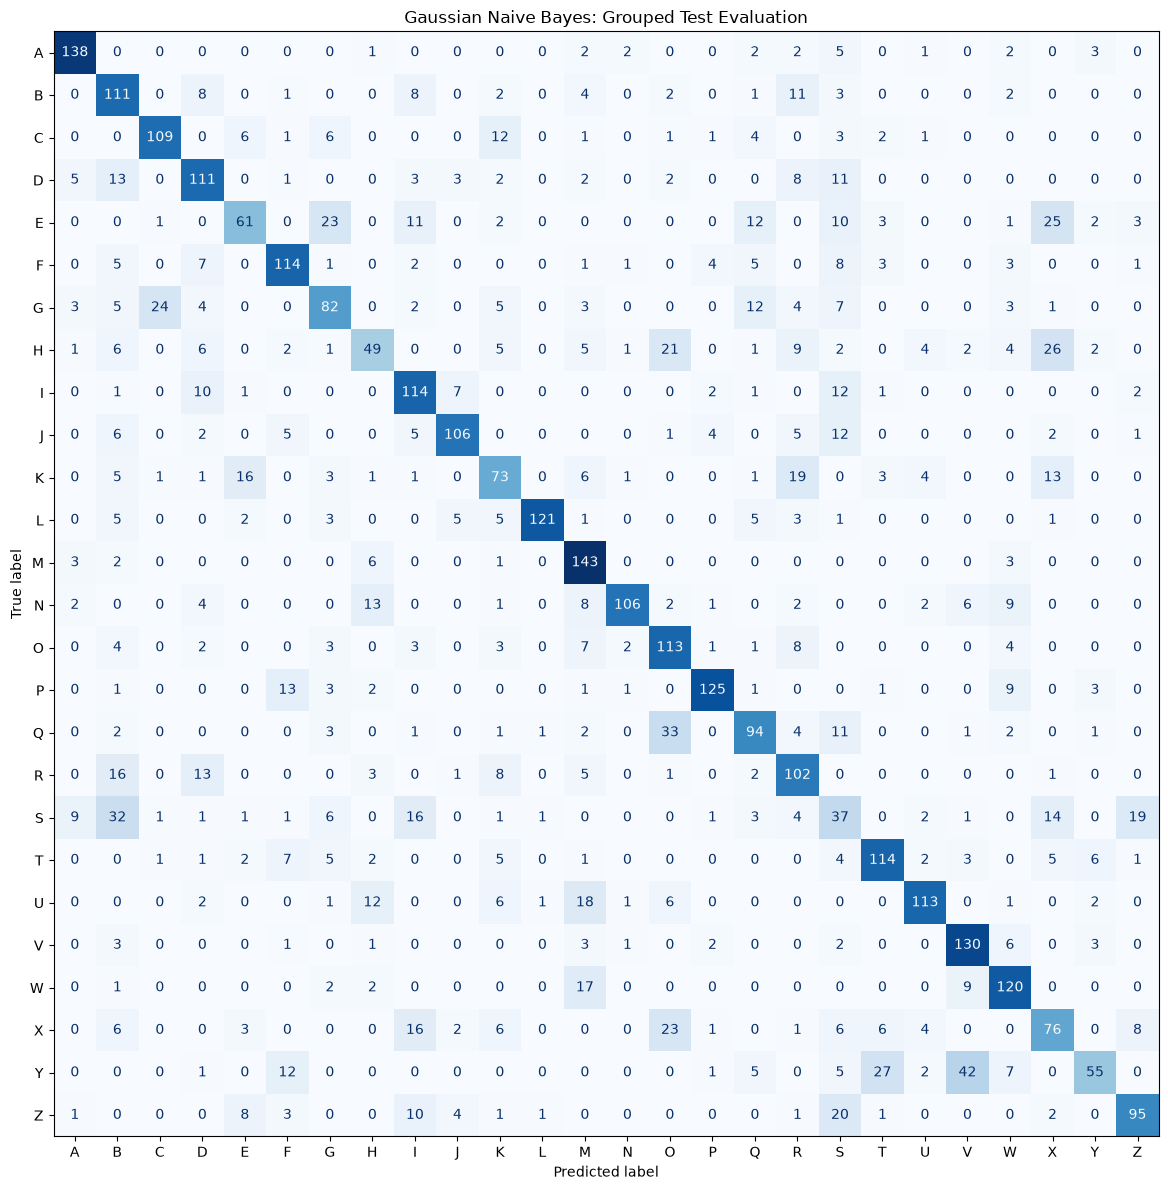

In [17]:
# Classification report for the grouped Gaussian model
print(
    classification_report(
        y_test_group,
        pred_gnb_group,
        labels=sorted(y.unique()),
        zero_division=0
    )
)

# Calculate grouped-split confusion matrix
cm_group = confusion_matrix(
    y_test_group,
    pred_gnb_group,
    labels=labels
)
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_group,
    display_labels=labels
)
disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)
plt.title("Gaussian Naive Bayes: Grouped Test Evaluation")
plt.tight_layout()
plt.show()

In [18]:
# Build a DataFrame from the grouped confusion matrix
cm_group_df = pd.DataFrame(
    cm_group,
    index=labels,
    columns=labels
)

# Make a writable copy and exclude correct predictions
group_errors = cm_group_df.to_numpy(copy=True)
np.fill_diagonal(group_errors, 0)

group_errors_df = pd.DataFrame(
    group_errors,
    index=labels,
    columns=labels
)

# Rank incorrect actual/predicted letter pairs
top_group_errors = (
    group_errors_df.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Most common grouped-test misclassifications:")
print(top_group_errors)

Most common grouped-test misclassifications:
Y  V    42
Q  O    33
S  B    32
Y  T    27
H  X    26
E  X    25
G  C    24
E  G    23
X  O    23
H  O    21
dtype: int64


In [19]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted F1-score"
    ],
    "Gaussian Naive Bayes": [
        accuracy_score(y_test_group, pred_gnb_group),
        precision_score(
            y_test_group, pred_gnb_group,
            average="macro", zero_division=0
        ),
        recall_score(
            y_test_group, pred_gnb_group,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test_group, pred_gnb_group,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test_group, pred_gnb_group,
            average="weighted", zero_division=0
        )
    ]
})
print(final_metrics.to_string(index=False))

           Metric  Gaussian Naive Bayes
         Accuracy              0.653000
  Macro Precision              0.665591
     Macro Recall              0.651988
   Macro F1-score              0.649262
Weighted F1-score              0.650335


In [20]:
# Reuse groups so identical feature vectors stay together
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Gaussian Naive Bayes across five folds
cv_scores = cross_val_score(
    GaussianNB(),
    X,
    y,
    cv=cv,
    groups=groups,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross-validation accuracy per fold:")
print(np.round(cv_scores, 4))

print(f"\nMean accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

Cross-validation accuracy per fold:
[0.653  0.6398 0.6472 0.637  0.64  ]

Mean accuracy: 0.6434
Standard deviation: 0.0059
